# Graph 3: Temperature — is the relationship linear?
Run `01_data_processing.ipynb` first.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
data = pd.read_pickle("processed/data.pkl")

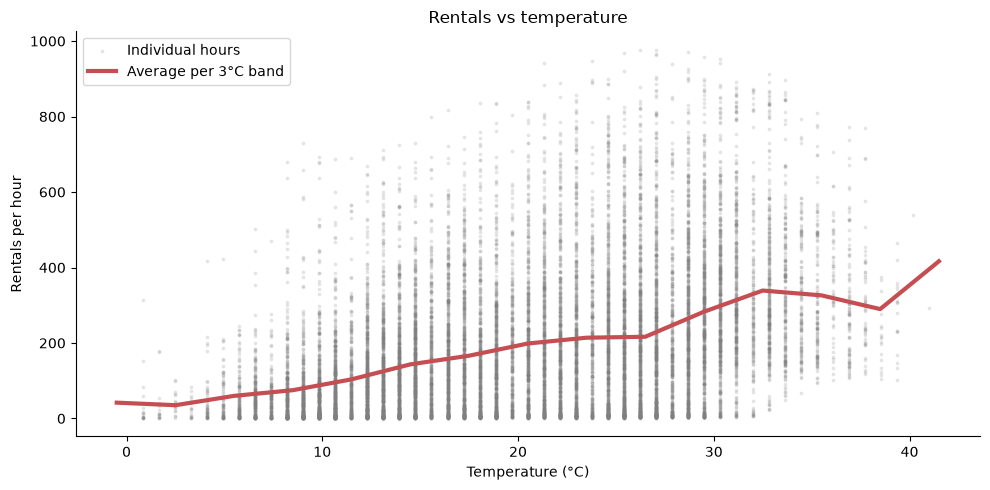

In [3]:
data["temp_band"] = pd.cut(data["temp_c"], bins=range(-5, 45, 3))
temp_curve = data.groupby("temp_band", observed=True)["cnt"].mean()

plt.scatter(data["temp_c"], data["cnt"], s=3, alpha=0.15, color="grey", label="Individual hours")
plt.plot([b.mid for b in temp_curve.index], temp_curve.values, color="#C44E52", lw=3, label="Average per 3°C band")
plt.title("Rentals vs temperature"); plt.xlabel("Temperature (°C)"); plt.ylabel("Rentals per hour")
plt.legend(); plt.tight_layout(); plt.savefig("figures/03_temperature.png", dpi=150); plt.show()